1. SUBMISSION: PREDICTIONS FOR BOTH CIRCUITS
Part A Prediction: Dominant outcomes will be '00' and '11' (~50% each).
Part B Prediction: Dominant outcomes will be '01' and '10' (~50% each).
Will all 4 outcomes appear? No. In an ideal quantum simulator, non-target states have 0 probability.

2. SUBMISSION: CIRCUIT FOR PART A
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

3. SUBMISSION: MEASUREMENT RESULTS FOR PART A (100 SHOTS)
Part A Counts: {'11': 59, '00': 41}

4. SUBMISSION: CIRCUIT FOR PART B
     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 

5. SUBMISSION: MEASUREMENT RESULTS FOR PART B (100 SHOTS)
Part B Counts: {'10': 55, '01': 45}


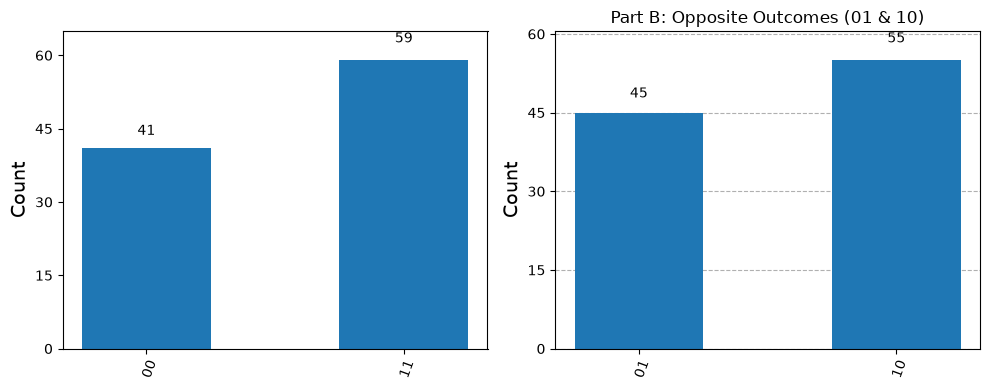


6. SUBMISSION: A COMPARISON OF THE TWO EXPERIMENTS
- Part A Experiment: Produces matching outcome states ('00' and '11').
- Part B Experiment: Produces opposite outcome states ('01' and '10').
- Key Difference: The additional X gate on qubit 1 reverses the second qubit's measurement.

7. SUBMISSION: SHORT EXPLANATION OF DIFFERENT CORRELATIONS
1. Part A correlation: The H and CNOT gates construct the Bell state (|00> + |11>)/sqrt(2). Both qubits are directly entangled, ensuring that measuring one qubit immediately forces the other to collapse into the exact same value ('00' or '11').
2. Part B correlation: Applying an X (NOT) gate to qubit 1 transforms the state into (|01> + |10>)/sqrt(2). The X gate inverts qubit 1 (|0> -> |1> and |1> -> |0>), switching the identical correlation into an opposite correlation ('01' or '10').


In [9]:

import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram

# Safe cross-version simulator import
try:
    from qiskit.providers.basic_provider import BasicSimulator

    simulator = BasicSimulator()

    def run_circuit(qc, shots=100):
        return simulator.run(qc, shots=shots).result().get_counts()

except ImportError:
    try:
        from qiskit_aer import AerSimulator

        simulator = AerSimulator()

        def run_circuit(qc, shots=100):
            return simulator.run(qc, shots=shots).result().get_counts()

    except ImportError:
        from qiskit import BasicAer, execute

        simulator = BasicAer.get_backend("qasm_simulator")

        def run_circuit(qc, shots=100):
            return execute(qc, simulator, shots=shots).result().get_counts()


# =====================================================================
# 1. PREDICTIONS FOR BOTH CIRCUITS
# =====================================================================
print("=" * 65)
print("1. SUBMISSION: PREDICTIONS FOR BOTH CIRCUITS")
print("=" * 65)
print("Part A Prediction: Dominant outcomes will be '00' and '11' (~50% each).")
print("Part B Prediction: Dominant outcomes will be '01' and '10' (~50% each).")
print(
    "Will all 4 outcomes appear? No. In an ideal quantum simulator, non-target states have 0 probability."
)


# =====================================================================
# 2. CIRCUIT FOR PART A & MEASUREMENT RESULTS (100 SHOTS)
# =====================================================================
qc_a = QuantumCircuit(2, 2)
qc_a.h(0)  # Hadamard on q0
qc_a.cx(0, 1)  # CNOT from q0 to q1
qc_a.measure([0, 1], [0, 1])

print("\n" + "=" * 65)
print("2. SUBMISSION: CIRCUIT FOR PART A")
print("=" * 65)
print(qc_a.draw())

counts_a = run_circuit(qc_a, shots=100)

print("\n" + "=" * 65)
print("3. SUBMISSION: MEASUREMENT RESULTS FOR PART A (100 SHOTS)")
print("=" * 65)
print("Part A Counts:", counts_a)


# =====================================================================
# 3. CIRCUIT FOR PART B & MEASUREMENT RESULTS (100 SHOTS)
# =====================================================================
qc_b = QuantumCircuit(2, 2)
qc_b.h(0)  # Hadamard on q0
qc_b.cx(0, 1)  # CNOT from q0 to q1
qc_b.x(1)  # X-gate on q1 (flips correlation)
qc_b.measure([0, 1], [0, 1])

print("\n" + "=" * 65)
print("4. SUBMISSION: CIRCUIT FOR PART B")
print("=" * 65)
print(qc_b.draw())

counts_b = run_circuit(qc_b, shots=100)

print("\n" + "=" * 65)
print("5. SUBMISSION: MEASUREMENT RESULTS FOR PART B (100 SHOTS)")
print("=" * 65)
print("Part B Counts:", counts_b)


# =====================================================================
# 4. HISTOGRAMS FOR BOTH CIRCUITS
# =====================================================================
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_histogram(counts_a, ax=ax[0], title="Part A: Correlated Outcomes (00 & 11)")
plot_histogram(counts_b, ax=ax[1], title="Part B: Opposite Outcomes (01 & 10)")
plt.tight_layout()
plt.show()


# =====================================================================
# 5. SUBMISSION: A COMPARISON OF THE TWO EXPERIMENTS
# =====================================================================
print("\n" + "=" * 65)
print("6. SUBMISSION: A COMPARISON OF THE TWO EXPERIMENTS")
print("=" * 65)
print("- Part A Experiment: Produces matching outcome states ('00' and '11').")
print("- Part B Experiment: Produces opposite outcome states ('01' and '10').")
print(
    "- Key Difference: The additional X gate on qubit 1 reverses the second qubit's measurement."
)

# Visual Comparison Plot
plot_histogram(
    [counts_a, counts_b],
    legend=["Part A (Correlated)", "Part B (Opposite)"],
    title="Side-by-Side Comparison of Part A and Part B",
)
plt.show()


# =====================================================================
# 6. SUBMISSION: SHORT EXPLANATION OF DIFFERENT CORRELATIONS
# =====================================================================
print("\n" + "=" * 65)
print("7. SUBMISSION: SHORT EXPLANATION OF DIFFERENT CORRELATIONS")
print("=" * 65)
print(
    "1. Part A correlation: The H and CNOT gates construct the Bell state (|00> + |11>)/sqrt(2). "
    "Both qubits are directly entangled, ensuring that measuring one qubit immediately forces "
    "the other to collapse into the exact same value ('00' or '11')."
)
print(
    "2. Part B correlation: Applying an X (NOT) gate to qubit 1 transforms the state into "
    "(|01> + |10>)/sqrt(2). The X gate inverts qubit 1 (|0> -> |1> and |1> -> |0>), "
    "switching the identical correlation into an opposite correlation ('01' or '10')."
)

